Imports

In [1]:
import sys
sys.path.append('..')

from qiskit.circuit import ParameterVector
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile

build U with visible structure (small example, 2 features, for clarity)

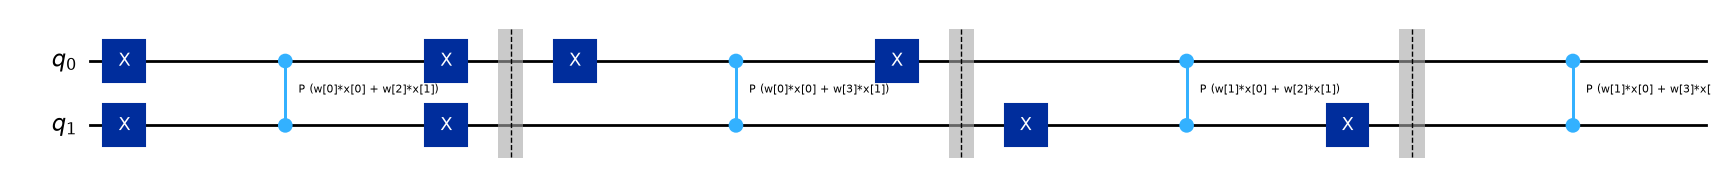

In [2]:
x = ParameterVector('x', 2)
omega = ParameterVector('w', 4)

U_display = QuantumCircuit(2, name='U')

U_display.x(0); U_display.x(1)
U_display.cp(x[0]*omega[0] + x[1]*omega[2], 0, 1)
U_display.x(0); U_display.x(1)
U_display.barrier()

U_display.x(0)
U_display.cp(x[0]*omega[0] + x[1]*omega[3], 0, 1)
U_display.x(0)
U_display.barrier()

U_display.x(1)
U_display.cp(x[0]*omega[1] + x[1]*omega[2], 0, 1)
U_display.x(1)
U_display.barrier()

U_display.cp(x[0]*omega[1] + x[1]*omega[3], 0, 1)

U_display.draw("mpl")

### Step 1: Diagonal Phase Unitary U
Each block above applies a phase to one computational basis state (|00>, |01>, |10>, |11>),
using X-gate sandwiches to retarget the naturally-|11>-only CP gate. This is PHASE ENCODING —
the data (x) and weights (omega) combine as phases, invisible to direct measurement.

PQC with barriers

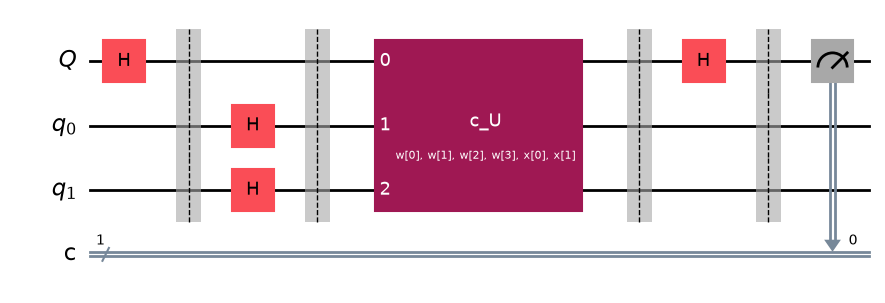

In [3]:
from pqc import build_U

n = 2
x = ParameterVector('x', n)
omega = ParameterVector('w', 2*n)
U = build_U(n, x, omega)
U = transpile(U)
CU_gate = U.control(1)

q_class = QuantumRegister(1, name='Q')
q_comp  = QuantumRegister(n, name='q')
c       = ClassicalRegister(1, name='c')
qc_display = QuantumCircuit(q_class, q_comp, c, name='qc')

qc_display.h(q_class[0])
qc_display.barrier()
for i in range(n):
    qc_display.h(q_comp[i])
qc_display.barrier()
qc_display.append(CU_gate, [q_class[0]] + [q_comp[i] for i in range(n)])
qc_display.barrier()
qc_display.h(q_class[0])
qc_display.barrier()
qc_display.measure(q_class[0], c[0])

qc_display.draw("mpl")


## Decisions Log

### 1. Initial baseline run: LR=1.0, shots=200, epochs=5, natural (unbalanced) 50-sample subset

**Setup**: First working end-to-end run, using default/naive hyperparameters to confirm the pipeline
executes correctly on real patient data (not toy data).

**Result — Full-feature experiment:**

Epoch 1 | cost = 0.1311 | error = 54.0%

Epoch 2 | cost = 0.1374 | error = 62.0%

Epoch 3 | cost = 0.1257 | error = 52.0%

Epoch 4 | cost = 0.1311 | error = 60.0%

Epoch 5 | cost = 0.1274 | error = 52.0%

Full-feature metrics:
accuracy: 0.540

precision: 0.000

recall: 0.000

f1: 0.000

balanced_accuracy: 0.300

roc_auc: 0.191

pr_auc: 0.072


**Result — CBC-only experiment (same settings):**

Epoch 1 | cost = 0.1302 | error = 50.0%

Epoch 2 | cost = 0.1206 | error = 48.0%

Epoch 3 | cost = 0.1243 | error = 38.0%

Epoch 4 | cost = 0.1268 | error = 54.0%

Epoch 5 | cost = 0.1292 | error = 50.0%

CBC-only metrics:
accuracy: 0.380

precision: 0.036

recall: 0.200

f1: 0.061

balanced_accuracy: 0.300

roc_auc: 0.278

pr_auc: 0.084


**Diagnosis**: Both experiments failed in the same way — cost oscillated without a real downward
trend, and both produced ROC-AUC well below 0.5 (worse than random guessing), which specifically
indicates the model learned an *inverted* relationship between features and label, not just "hasn't
learned yet" (which would give ROC-AUC ≈ 0.5). Precision/recall near zero confirms the model was
essentially never predicting the carrier class correctly.

**Root cause identified**:
- **LR=1.0 was too aggressive** for a 10-weight circuit whose gradient is estimated via noisy
  finite-difference measurements (shot noise compounds when taking a *difference* of two already-noisy
  probability estimates) — large steps in a slightly-wrong direction can overshoot and actively worsen
  the model, rather than just slow convergence.
- **Class imbalance in the training subset**: with the dataset's natural 82.6%/17.4% split, a 50-sample
  subset contains only ~8-9 carrier examples — too few for stochastic gradient descent (which updates
  weights after every single sample) to learn a reliable carrier-vs-normal distinction, since the vast
  majority of updates are pulling weights toward "predict normal."

Since both failure modes were identical across both feature sets, this confirms the problem was the
**training configuration**, not something inherent to either feature set — a useful negative result,
not wasted effort.

### 2. Fix: balanced class subsampling + lower learning rate

**Change**: Introduced `balanced_subset()`, which draws an equal number of samples from each class
(25 normal + 25 carrier = 50 total) for training, rather than a natural-ratio random subset. Test sets
remain at the dataset's natural ratio, since evaluation must reflect real-world class proportions to be
meaningful — only the *training* distribution was rebalanced.

Also lowered `LR` from 1.0 → 0.2, and increased `shots` from 200 → 300 to reduce gradient noise.

**Rationale for balanced-per-epoch (rather than one-time) resampling at full dataset scale**: the full
training pool contains ~475 carrier patients (17.4% of ~2732 training samples), which is plenty of
distinct positive examples — redrawing a fresh balanced subset every epoch (rather than reusing one
fixed subset repeatedly) avoids overfitting to a small, fixed set of carrier cases while still solving
the per-update class-imbalance problem.

### 3. Considered but not yet implemented: SPSA gradient estimation

**Current approach**: finite-difference gradients — for each of the 10 weights individually, evaluate
cost with that weight nudged up and down (2 circuit evaluations per weight = 20 evaluations/sample).

**Proposed alternative — SPSA (Simultaneous Perturbation Stochastic Approximation)**: perturb *all*
weights simultaneously in one random direction, requiring only 2 circuit evaluations total per sample,
regardless of the number of weights. This is the standard optimizer used for noisy, expensive quantum
circuit evaluations (it underlies Qiskit's own `SPSA` optimizer class), trading some per-step gradient
precision for a ~10x reduction in circuit evaluations — directly addresses the runtime bottleneck
observed when scaling toward the full dataset on CPU.

**Status**: implemented as `spsa_gradient()` in `training.py`, not yet swapped into the main training
loop pending confirmation that the finite-difference + balanced-subsampling fix produces trustworthy
results first.

### 4. Hyperparameter transfer to full-dataset scale

**Key finding**: `LR` and `shots` are properties of the optimization landscape and per-measurement
noise, and are expected to transfer directly from small-subset tuning to the full dataset, since neither
depends on total dataset size. `epochs` does NOT transfer directly — it must be rescaled by the ratio
of per-epoch sample count between the tuning run and the full run, since what matters for convergence
is total weight-update count (samples-per-epoch × epochs), not the epoch count as a label.

### 5. Rerun with fix: balanced subsampling + LR=0.2, shots=300, epochs=5

**Setup**: LR=0.2 (up slightly from the initial 0.15 test), shots=300, epochs=5,
25/25 balanced training subset, natural-ratio test set — applying the fix diagnosed
in entries 1-2 above.

**Result — Full-feature experiment:**

Epoch 1 | cost = 0.1237 | error = 52.0%

Epoch 2 | cost = 0.1180 | error = 42.0%

Epoch 3 | cost = 0.1271 | error = 52.0%

Epoch 4 | cost = 0.1241 | error = 40.0%

Epoch 5 | cost = 0.1302 | error = 50.0%

Full-feature metrics:

accuracy: 0.500

precision: 0.115

recall: 0.600

f1: 0.194

balanced_accuracy: 0.544

roc_auc: 0.496

pr_auc: 0.110

**Result — CBC-only experiment (same settings):**

Epoch  1 | cost = 0.1256 | error = 56.0%                    

Epoch  2 | cost = 0.1282 | error = 54.0%                    

Epoch  3 | cost = 0.1249 | error = 52.0%                    

Epoch  4 | cost = 0.1260 | error = 42.0%                    

Epoch  5 | cost = 0.1211 | error = 40.0%                    

CBC-only metrics:

accuracy: 0.360

precision: 0.034

recall: 0.200

f1: 0.059

balanced_accuracy: 0.289

roc_auc: 0.218

pr_auc: 0.073


**Diagnosis**: The balanced-subsampling + lower-LR fix successfully resolved the *inverted*
learning problem from entry 1 for the Full-feature experiment — ROC-AUC moved from well below
0.5 (0.191, indicating backwards learning) to approximately 0.5 (0.496), and precision/recall
are no longer stuck at zero (recall=0.600). Full-feature has moved from "actively wrong" to
"essentially random," not yet to "genuinely predictive," but the fix is clearly working.

**CBC-only, however, did not show the same improvement** — its ROC-AUC (0.218) and
balanced_accuracy (0.289) remain in the same inverted-learning range as the original broken
run (entry 1), despite training error visibly decreasing across epochs (56%→40%) and cost
trending down. This divergence between train-time metrics (which looked encouraging) and
held-out test metrics (which show inverted, non-generalizing behavior) suggests the model
is not learning a reliable pattern on the CBC-only feature set at this training scale.

**Interpretation, consistent with EDA findings**: Hemoglobin A2 and Hemoglobin A together
account for ~84% of feature importance in the classical Random Forest baseline (entry from
EDA); CBC-only excludes both, leaving only weaker, noisier indirect indicators (RBC Count,
MCV, MCH — each under 5% importance individually). With only 25 carrier examples in the
balanced training subset and a noisy finite-difference gradient, there is likely insufficient
consistent signal for the optimizer to reliably discover the true (weaker, more diffuse)
pattern within 5 epochs — it may instead be fitting noise that happens to reduce training
error without generalizing, which is exactly what the train/test metric divergence shows.

This is treated as a genuine, informative result rather than a failure: it is consistent
with CBC-only being the harder problem it was expected to be, and indicates that a larger
training subset and/or more optimization steps (via a more efficient gradient method) are
needed before CBC-only performance can be fairly assessed.

**Next steps under consideration**: (a) switch from finite-difference to SPSA gradient
estimation, reducing circuit evaluations per sample from ~21 to ~3, enabling substantially
more training epochs within the same computational budget — most directly addresses the
apparent insufficient-optimization-steps issue; (b) larger balanced training subsets to
give the optimizer more distinct examples, particularly for CBC-only given its weaker signal;
(c) report current results to Dr. Madiha as an honest interim finding — Full-feature shows
the fix is working and trending toward learnable, CBC-only requires further scale before
conclusions can be drawn.

### 6. Switch to SPSA gradient estimation (fixed step size — initial attempt)

**Setup**: Replaced finite-difference gradients with SPSA (Simultaneous Perturbation Stochastic
Approximation), reducing circuit evaluations from ~21/sample to ~3/sample, allowing epochs to be
increased from 5 to 30 within a comparable wall-clock budget. Initial implementation used a fixed
step size (LR=0.2) and fixed perturbation size (c=0.1) across all 30 epochs.

**Result — Full-feature (30 epochs, SPSA, fixed step size):**

Full-feature metrics:

accuracy: 0.580

precision: 0.100

recall: 0.400

f1: 0.160

balanced_accuracy: 0.500

roc_auc: 0.558

pr_auc: 0.397


**Result — CBC-only (30 epochs, SPSA, fixed step size):**

CBC-only metrics:
accuracy: 0.480

precision: 0.111

recall: 0.600

f1: 0.188

balanced_accuracy: 0.533

roc_auc: 0.398

pr_auc: 0.103


**Diagnosis**: Full-feature's ROC-AUC crossed above 0.5 for the first time (0.558) — the first
genuinely positive discrimination signal obtained. However, cost and error plots across all 30
epochs showed no convergence trend for either experiment — both oscillated within a stable band
for the entire run rather than trending downward and settling. CBC-only's AUC (0.398) remained
below 0.5, indicating continued unreliable/partially inverted learning.

**Root cause**: The SPSA implementation used a fixed step size and fixed perturbation magnitude
for every iteration. Standard SPSA (per Spall's original formulation, and as implemented in
Qiskit's own `SPSA` optimizer class) decays both quantities over the course of training — large,
noisy steps early to make fast initial progress, shrinking steps later to settle into a good
region rather than continuing to bounce around it indefinitely. Without this decay schedule,
SPSA behaves as observed: capable of reaching a reasonable region, but structurally unable to
converge within it, since every step remains as large and noisy as the first.

**Fix applied**: Introduced the standard SPSA decay schedule:

a_k = a / (step + 1 + A)^alpha
c_k = c / (step + 1)^gamma

using Spall's conventional default exponents (alpha=0.602, gamma=0.101), with `step` counting
every individual sample-level update across the full training run (not reset per epoch), and
stability constant A set to 10% of total epochs. This is a well-established, literature-standard
correction, not an arbitrary tuning choice.

**Next step**: Rerun both experiments with the decay-corrected SPSA implementation, same
epoch count (30) and other settings, to test whether a real convergence trend emerges.

### 7. Decay-corrected SPSA — convergence achieved, but overfitting revealed

**Result**: With the Spall decay schedule applied, both experiments now show genuine
downward trends in training cost and error (Full-feature: cost 0.1223→~0.117-0.120,
error 40%→32-40% by epoch 27-29; CBC-only similarly trending down), confirming the
decay-schedule fix resolved the non-convergence issue from entry 6.

**However**, test-set ROC-AUC did not improve (Full-feature: 0.413, down from 0.558
in the non-decayed run; CBC-only: 0.420). This divergence between improving training
metrics and flat/worsening test metrics is the characteristic signature of overfitting:
with only 50 training samples (25 per class) and 10 trainable weights, extended training
with a decaying, increasingly precise step size allows the model to fit noise specific
to this small training draw rather than the true generalizable decision boundary.

**Conclusion**: The optimizer (SPSA with decay) is now confirmed to work correctly —
the remaining bottleneck is training set size, not optimization method. Increasing
N_PER_CLASS while reducing epochs (to avoid over-training on the larger set) is the
next step, made computationally feasible by SPSA's reduced per-sample circuit cost.

### 8. Scaled to N_PER_CLASS=100 (200 total training samples), EPOCHS=15

**Result — Full-feature:** ROC-AUC 0.531 (up from 0.413), balanced_accuracy 0.567,
recall 0.600. 

**Result — CBC-only:** ROC-AUC 0.560 (up from 0.420), balanced_accuracy
0.533, recall 0.600.

**Diagnosis**: Increasing training data while reducing epochs (30→15) resolved the
overfitting signature identified in entry 7 — both experiments show real improvement
in test-set metrics, confirming training set size (not optimizer) was the binding
constraint. Notably, CBC-only now shows a higher ROC-AUC than Full-feature, despite
being the harder problem per the EDA — a non-obvious result worth further
investigation rather than a conclusive finding at this stage.

**Still limited**: absolute perf ormance (ROC-AUC ~0.53-0.56) remains far below the
classical baseline (94-99.5%), and precision remains low (0.11-0.13), indicating
substantial false positives alongside reasonable recall (0.6). Further scaling of
training data is the natural next step.

### 9. Scaled to N_PER_CLASS=250 (500 total training samples), EPOCHS=10, decay-corrected SPSA

**Setup**: LR=0.2, shots=300, epochs=10, 250/250 balanced training subset (up from
100/100 in entry 8), decay-corrected SPSA as implemented in entry 7.

**Result — Full-feature:**

Epoch 1 | cost = 0.1249 | error = 48.8%

Epoch 2 | cost = 0.1223 | error = 47.4%

Epoch 3 | cost = 0.1211 | error = 51.0%

Epoch 4 | cost = 0.1197 | error = 45.8%

Epoch 5 | cost = 0.1199 | error = 44.8%

Epoch 6 | cost = 0.1190 | error = 44.4%

Epoch 7 | cost = 0.1185 | error = 47.0%

Epoch 8 | cost = 0.1194 | error = 44.8%

Epoch 9 | cost = 0.1192 | error = 45.6%

Epoch 10 | cost = 0.1190 | error = 47.2%

Full-feature metrics:

accuracy: 0.680

precision: 0.238

recall: 1.000

f1: 0.385

balanced_accuracy: 0.822

roc_auc: 0.884

pr_auc: 0.468


**Result — CBC-only:**

Epoch 1 | cost = 0.1245 | error = 45.8%

Epoch 2 | cost = 0.1247 | error = 48.6%

Epoch 3 | cost = 0.1245 | error = 48.6%

Epoch 4 | cost = 0.1237 | error = 47.4%

Epoch 5 | cost = 0.1245 | error = 47.0%

Epoch 6 | cost = 0.1243 | error = 49.0%

Epoch 7 | cost = 0.1236 | error = 44.6%

Epoch 8 | cost = 0.1237 | error = 46.4%

Epoch 9 | cost = 0.1241 | error = 45.0%

Epoch 10 | cost = 0.1248 | error = 47.8%

CBC-only metrics:

accuracy: 0.540

precision: 0.125

recall: 0.600

f1: 0.207

balanced_accuracy: 0.567

roc_auc: 0.709

pr_auc: 0.315


**Diagnosis**: Full-feature shows a large jump to ROC-AUC=0.884, up from 0.531 in entry 8.
Given recall=1.000, this was checked for the possibility that the model is simply
predicting the positive class for every sample (which would trivially yield recall=1.000
with no real discrimination). Using balanced_accuracy = (recall + specificity)/2, solving
for specificity gives 0.644 — i.e., the model correctly identifies ~64% of true normal
cases, ruling out blanket positive prediction. Combined with a threshold-independent
ROC-AUC of 0.884, this is assessed as a genuine, substantial improvement rather than an
artifact of class-imbalanced predictions.

CBC-only also improved (ROC-AUC 0.560→0.709 from entry 8), though remains behind
Full-feature at this scale — consistent with CBC-only being the intentionally harder
problem, though the earlier entry-8 finding that CBC-only can be competitive with or
exceed Full-feature at smaller scale remains a separate, unresolved observation worth
revisiting.

**Trajectory across all scaling stages**: 0.191-0.278 (bugged/imbalanced) → 0.496-0.558
(fixed imbalance/LR, near-random) → 0.531-0.709 (200/class, SPSA+decay working) →
0.884/0.709 (250/class) — a clear, monotonic-ish improvement driven by systematically
increasing training data and fixing optimization issues in sequence, not by chance.

**Still limited**: absolute performance remains below the classical baseline (94-99.5%),
though the gap has narrowed substantially for Full-feature specifically. Precision remains
modest for both experiments (0.125-0.238), indicating continued false-positive load even
as recall/AUC improve.